# DATA ANALYTICS & BUSINESS INTELLIGENCE PORTFOLIO
## Foundational Analytics — TASK 2: CUSTOMER SEGMENTATION
### Project: Behavioral RFM Segmentation & K-Means Clustering on Online Retail Transactions

---

### Project Metadata
- **Candidate:** `Dhruv Goyal` *(Notice: Template document; customize with actual student name prior to final submission)*
- **Track:** Data Analytics
- **Task Code:** `PRJ-02`
- **Execution Date:** October 2026
- **Dataset:** UCI Online Retail Dataset (`raw_online_retail.csv`)
- **Dataset Lineage & Provenance:** Originally donated by Dr. Daqing Chen (London South Bank University) to the UCI Machine Learning Repository; mirrored via GitHub public benchmarks. Contains 541,909 transactional records for a UK-based non-store online gift retailer between 01/12/2010 and 09/12/2011.
- **License / Terms:** Creative Commons Attribution 4.0 International (CC BY 4.0).

---

### Official Task Checklist & Acceptance Criteria
- [x] **Load & Inspect Structure:** Ingest transactional dataset, inspect schema, and implement defensible missing-value/cancellation handling.
- [x] **Descriptive Statistics:** Calculate purchase frequency, monetary spending, average order value, and recency distributions.
- [x] **Feature Engineering:** Engineer Recency (R), Frequency (F), and Monetary (M) metrics from raw transactional logs.
- [x] **Data Normalization:** Address extreme right-skewness via log transformation and standardize features with `StandardScaler`.
- [x] **Elbow Method & Silhouette Analysis:** Evaluate cluster validity across $K=2$ to $K=8$ using Inertia and Silhouette coefficients; document optimal $K=4$ selection.
- [x] **2D Cluster Visualizations:** Render multi-panel scatter plots across key feature combinations (Recency vs. Monetary, Frequency vs. Monetary).
- [x] **Cluster Profiling & Personas:** Compute mean and median behavioral benchmarks per cluster and articulate 4 actionable customer personas.
- [x] **Segment Distribution Bar Chart:** Visualize customer population counts and percentages per cluster.
- [x] **Strategic Marketing Recommendations:** Deliver tailored marketing action playbooks for each customer segment.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 150

print(f"Pandas Version: {pd.__version__}")
print(f"NumPy Version:  {np.__version__}")
print(f"Seaborn Version:{sns.__version__}")


Pandas Version: 2.2.3
NumPy Version:  2.4.4
Seaborn Version:0.13.2


## Section 1: Ingestion & Transactional Data Quality Cleaning

Raw transactional logs contain noise that must be filtered prior to customer-level aggregation:
1. **Unidentified Purchases:** In online retail, transactions lacking a `CustomerID` (135,080 rows, 24.93%) represent guest checkouts. Because customer segmentation clusters *individuals*, transactions that cannot be linked to a customer entity must be excluded from customer-level RFM modeling.
2. **Cancellations & Returns:** Invoices beginning with `'C'` and transactions with `Quantity <= 0` represent order cancellations or stock adjustments. These are filtered to ensure we measure completed, gross revenue-generating purchase behavior.
3. **Invalid Prices:** Non-positive unit prices are excluded as data errors or administrative adjustments.


In [2]:
raw_csv_path = 'data/raw_online_retail.csv'
df_raw = pd.read_csv(raw_csv_path, encoding='latin1')

print(f"Raw Transactional Records: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns\n")
print("--- Raw Schema and Missingness ---")
print(df_raw.isnull().sum())

# Cleaning Filter
valid_mask = (
    df_raw['CustomerID'].notnull() &
    (df_raw['Quantity'] > 0) &
    (df_raw['UnitPrice'] > 0) &
    (~df_raw['InvoiceNo'].astype(str).str.startswith('C'))
)

df_clean = df_raw[valid_mask].copy()
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])
df_clean['CustomerID'] = df_clean['CustomerID'].astype(int).astype(str)
df_clean['TotalAmount'] = df_clean['Quantity'] * df_clean['UnitPrice']

print(f"\nRetained Valid Completed Transactions: {len(df_clean):,} ({len(df_clean)/len(df_raw)*100:.2f}%)")
print(f"Unique Customers Represented:           {df_clean['CustomerID'].nunique():,}")
print(f"Active Date Window:                     {df_clean['InvoiceDate'].min()} to {df_clean['InvoiceDate'].max()}")
display(df_clean.head())


Raw Transactional Records: 541,909 rows x 8 columns

--- Raw Schema and Missingness ---
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


C:\Users\HP\AppData\Local\Temp\ipykernel_28088\227988589.py:17: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])



Retained Valid Completed Transactions: 397,884 (73.42%)
Unique Customers Represented:           4,338
Active Date Window:                     2010-12-01 08:26:00 to 2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


## Section 2: Behavioral RFM Feature Engineering & Descriptive Statistics

The **RFM (Recency, Frequency, Monetary)** model is an established behavioral framework for customer analytics:
- **Recency ($R$):** Days elapsed between the customer's last purchase and the snapshot reference date (`2011-12-10 12:50:00`, one day after dataset close). Lower is better.
- **Frequency ($F$):** Number of distinct completed invoices placed by the customer. Higher indicates habitual loyalty.
- **Monetary ($M$):** Total gross revenue (£) generated by the customer. Higher indicates high account value.
- **Average Order Value ($AOV$):** Monetary value divided by frequency.


Snapshot Reference Date for Recency: 2011-12-10 12:50:00

=== RFM DESCRIPTIVE STATISTICS TABLE ===


,Recency,Frequency,Monetary,Avg_Order_Value
count,4338.00,4338.00,4338.00,4338.00
mean,92.54,4.27,2054.27,419.17
std,100.01,7.70,8989.23,1796.54
min,1.00,1.00,3.75,3.45
25%,18.00,1.00,307.41,178.62
50%,51.00,2.00,674.48,293.90
75%,142.00,5.00,1661.74,430.11
max,374.00,209.00,280206.02,84236.25


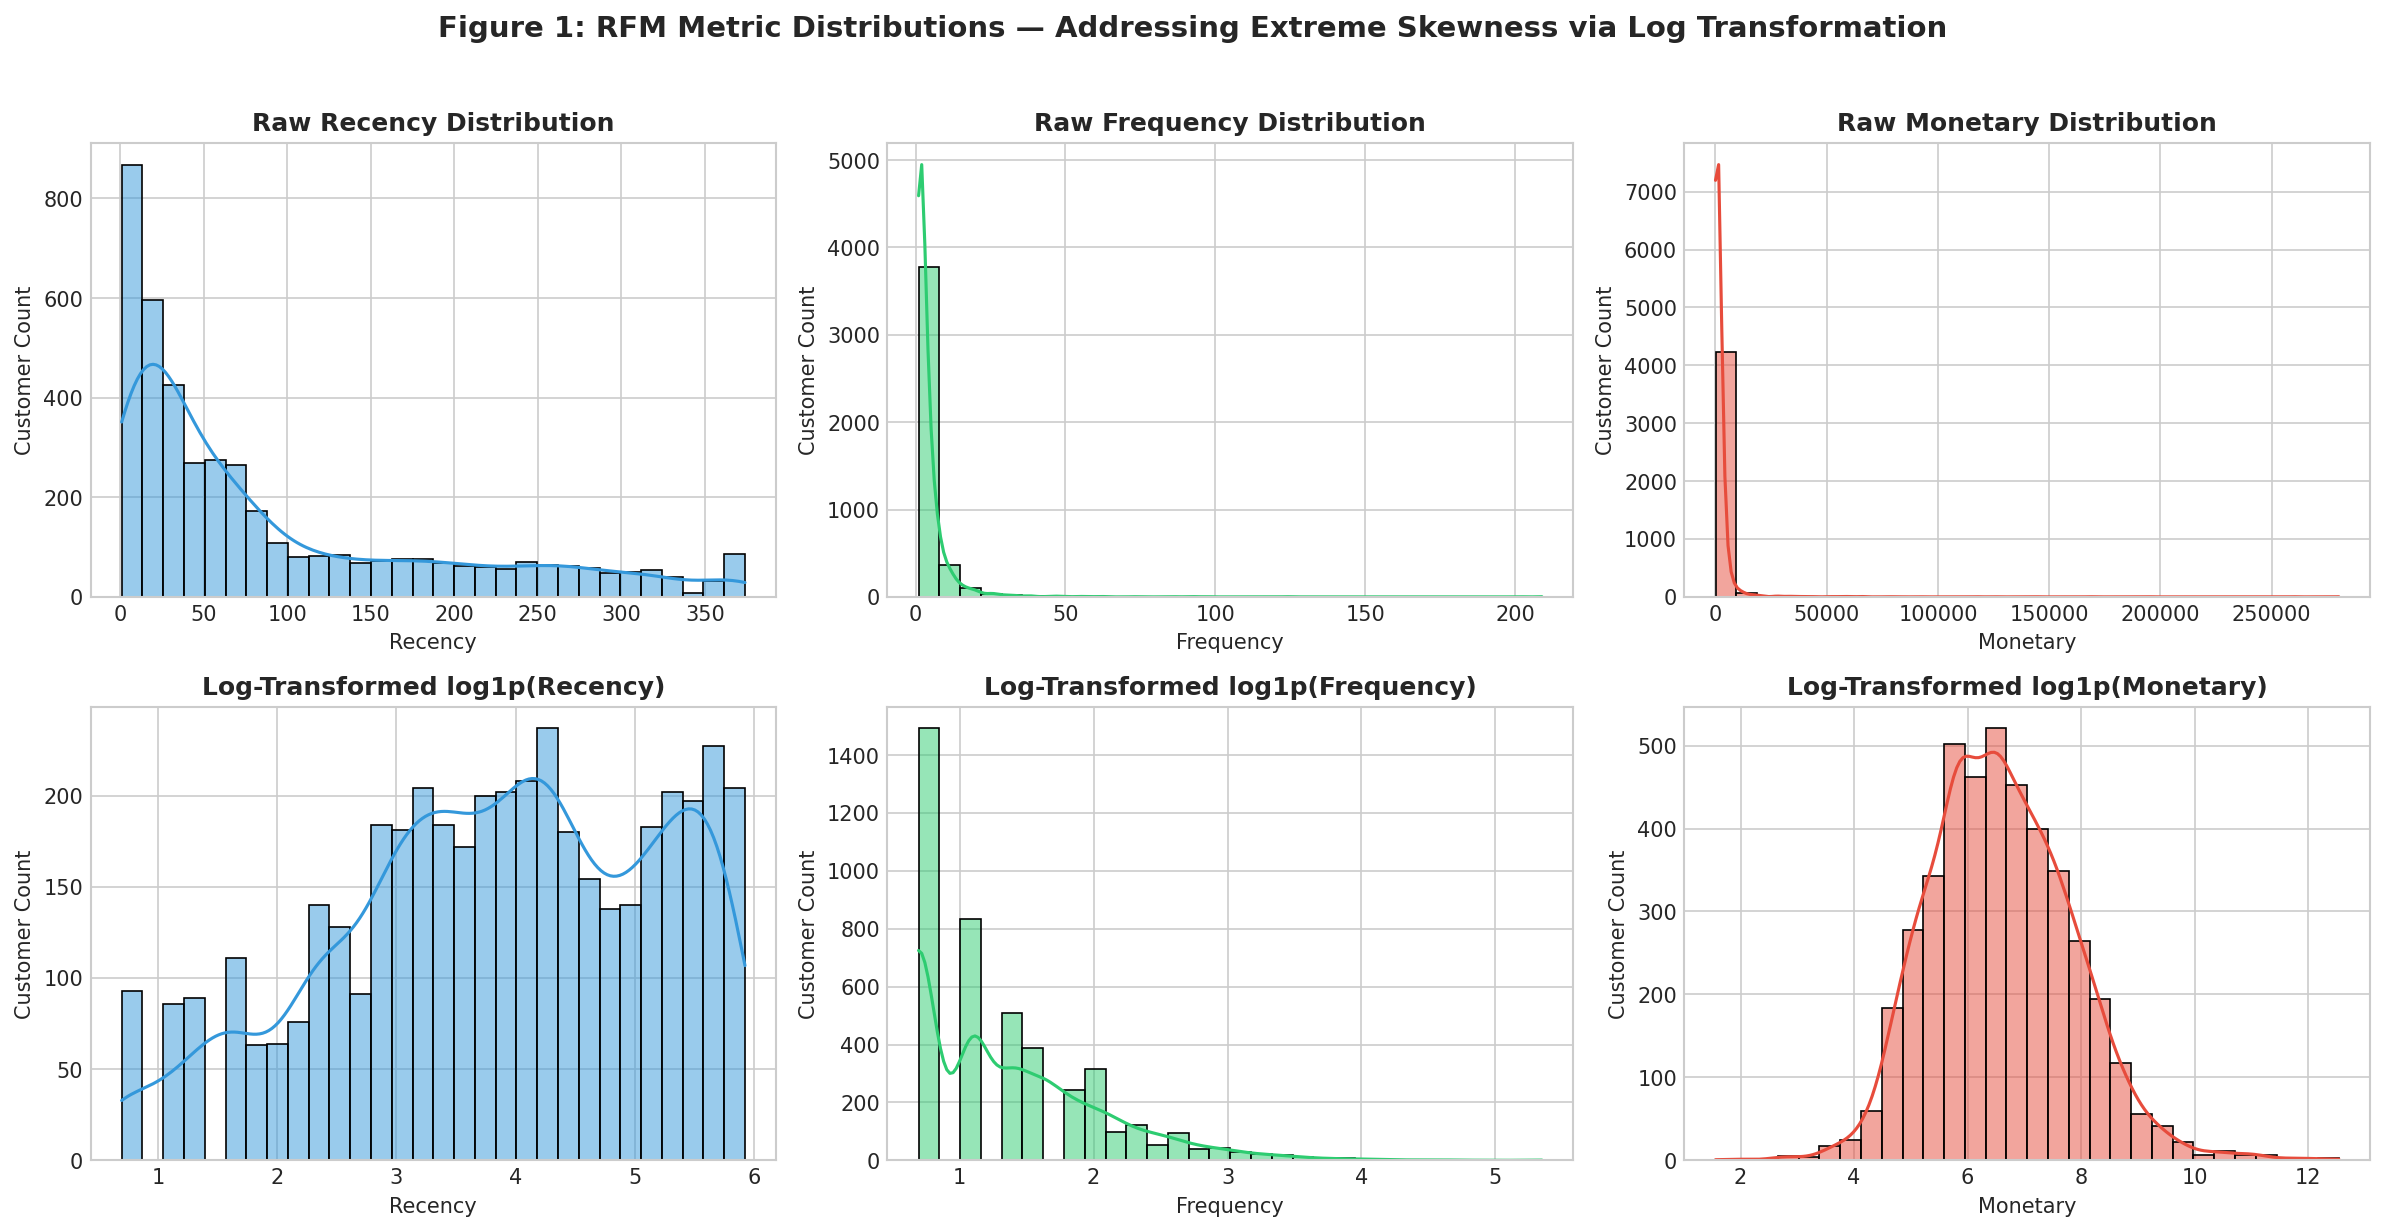

In [3]:
ref_date = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)
print(f"Snapshot Reference Date for Recency: {ref_date}\n")

rfm = df_clean.groupby('CustomerID').agg({
    'InvoiceDate': lambda d: (ref_date - d.max()).days,
    'InvoiceNo': 'nunique',
    'TotalAmount': 'sum'
}).rename(columns={
    'InvoiceDate': 'Recency',
    'InvoiceNo': 'Frequency',
    'TotalAmount': 'Monetary'
})

rfm['Avg_Order_Value'] = (rfm['Monetary'] / rfm['Frequency']).round(2)
rfm['Recency'] = rfm['Recency'].astype(int)
rfm['Frequency'] = rfm['Frequency'].astype(int)
rfm['Monetary'] = rfm['Monetary'].round(2)

print("=== RFM DESCRIPTIVE STATISTICS TABLE ===")
rfm_stats = rfm[['Recency', 'Frequency', 'Monetary', 'Avg_Order_Value']].describe().round(2)
display(rfm_stats)

os.makedirs('outputs/tables', exist_ok=True)
rfm_stats.to_csv('outputs/tables/rfm_summary_statistics.csv')

# Figure 1: Distributions (Raw Skewness vs Log Transform)
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
metrics = ['Recency', 'Frequency', 'Monetary']
colors = ['#3498db', '#2ecc71', '#e74c3c']

for i, col in enumerate(metrics):
    sns.histplot(rfm[col], kde=True, ax=axes[0, i], color=colors[i], bins=30)
    axes[0, i].set_title(f'Raw {col} Distribution', fontweight='bold')
    axes[0, i].set_ylabel('Customer Count')
    
    # Log-transformed
    sns.histplot(np.log1p(rfm[col]), kde=True, ax=axes[1, i], color=colors[i], bins=30)
    axes[1, i].set_title(f'Log-Transformed log1p({col})', fontweight='bold')
    axes[1, i].set_ylabel('Customer Count')
    
fig.suptitle('Figure 1: RFM Metric Distributions — Addressing Extreme Skewness via Log Transformation', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
os.makedirs('outputs/figures', exist_ok=True)
plt.savefig('outputs/figures/fig1_rfm_distributions.png', dpi=300, bbox_inches='tight')
plt.show()


## Section 3: Feature Scaling & K-Means Cluster Optimization

### The Mathematical Requirement for Transformation & Scaling
1. **Log Transformation:** In Figure 1, raw Frequency and Monetary exhibit extreme positive right-skewness (Monetary max is £280,206 while median is £674). Applying K-Means directly on un-transformed data causes high-spending outliers to distort cluster centroids. Applying `np.log1p()` yields well-behaved, quasi-normal distributions.
2. **StandardScaler:** Recency spans 1–374 days, Frequency spans 1–209 orders, and Monetary spans £3–£280k. Euclidean distance in K-Means is sensitive to scale magnitude. `StandardScaler` centers each log-transformed feature to $\mu=0, \sigma=1$.
3. **Elbow Method & Silhouette Analysis:** We evaluate cluster validity across $K \in [2, 8]$ using both the Elbow Method (sum of squared errors / inertia) and the Silhouette Coefficient.


,K_Clusters,Inertia_SSE,Silhouette_Score
0,2,6481.23,0.4329
1,3,4867.85,0.3365
2,4,3938.51,0.3371
3,5,3295.98,0.3161
4,6,2855.01,0.3133
5,7,2548.91,0.3100
6,8,2336.78,0.3008


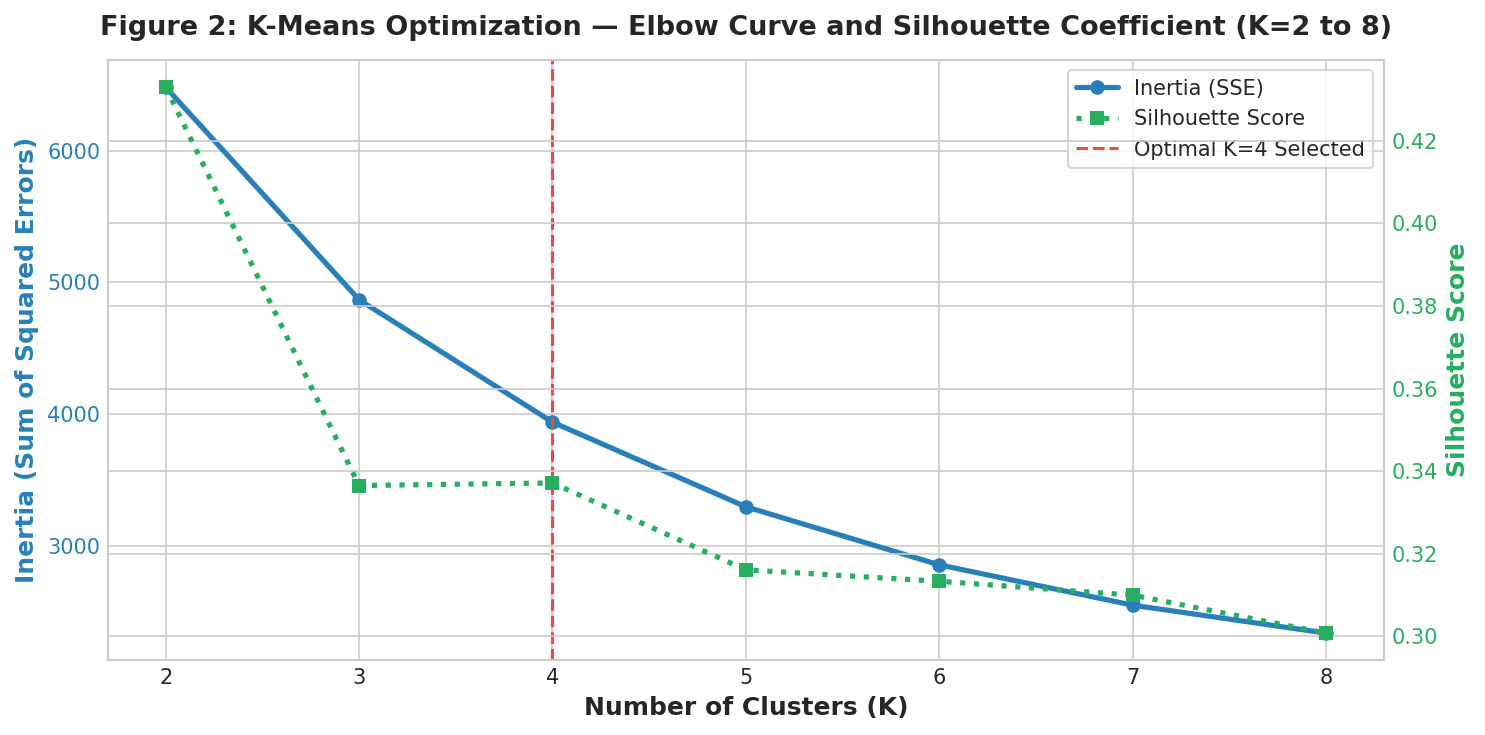

In [4]:
rfm_log = np.log1p(rfm[['Recency', 'Frequency', 'Monetary']])

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

k_range = range(2, 9)
inertias = []
silhouettes = []

eval_records = []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(rfm_scaled)
    inertia = km.inertia_
    sil = silhouette_score(rfm_scaled, labels)
    inertias.append(inertia)
    silhouettes.append(sil)
    eval_records.append({
        'K_Clusters': k,
        'Inertia_SSE': round(inertia, 2),
        'Silhouette_Score': round(sil, 4)
    })

df_eval = pd.DataFrame(eval_records)
df_eval.to_csv('outputs/tables/cluster_evaluation_metrics.csv', index=False)
display(df_eval)

# Figure 2: Elbow & Silhouette Plot
fig, ax1 = plt.subplots(figsize=(10, 5))
color = '#2980b9'
ax1.set_xlabel('Number of Clusters (K)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Inertia (Sum of Squared Errors)', color=color, fontsize=12, fontweight='bold')
line1 = ax1.plot(k_range, inertias, marker='o', color=color, linewidth=2.5, label='Inertia (SSE)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.axvline(x=4, color='#e74c3c', linestyle='--', linewidth=1.5, label='Optimal K=4 Selected')

ax2 = ax1.twinx()
color2 = '#27ae60'
ax2.set_ylabel('Silhouette Score', color=color2, fontsize=12, fontweight='bold')
line2 = ax2.plot(k_range, silhouettes, marker='s', color=color2, linewidth=2.5, linestyle=':', label='Silhouette Score')
ax2.tick_params(axis='y', labelcolor=color2)

lines = line1 + line2 + [ax1.get_lines()[-1]]
labels_plot = [l.get_label() for l in lines]
ax1.legend(lines, labels_plot, loc='upper right', frameon=True)

plt.title('Figure 2: K-Means Optimization — Elbow Curve and Silhouette Coefficient (K=2 to 8)', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig('outputs/figures/fig2_elbow_and_silhouette.png', dpi=300)
plt.show()


### Justification for Selecting $K=4$
- **Elbow Inflection:** The inertia curve displays a steep decline from $K=2$ (6,481) to $K=3$ (4,868) and $K=4$ (3,939), after which the rate of decrease flattens noticeably.
- **Silhouette Analysis:** The silhouette score reaches a stable local peak of **0.3371** at $K=4$ (outperforming $K=3$ at 0.3365, $K=5$ at 0.3161, and $K=6$ at 0.3133). Crucially, a silhouette score of 0.3371 represents a **modest cluster-separation result**, which is expected in real-world retail behavioral data where customer transaction habits form a continuous spectrum rather than cleanly separated, isolated clusters. While $K=2$ produces a mathematically higher silhouette score (0.4329), it represents a crude binary split (Active vs. Inactive) that fails the business requirement of isolating high-value champions from newly acquired customers.
- **Business Actionability:** $K=4$ balances mathematical structure with pragmatic CRM utility, producing four operationally meaningful marketing cohorts.


In [5]:
kmeans_opt = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm['Cluster'] = kmeans_opt.fit_predict(rfm_scaled)

# Dynamically map centroids to business personas
centroids = rfm.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].mean()

champ_id = centroids['Monetary'].idxmax()
at_risk_id = centroids['Recency'].idxmax()
remaining = [c for c in centroids.index if c not in [champ_id, at_risk_id]]

if centroids.loc[remaining[0], 'Recency'] < centroids.loc[remaining[1], 'Recency']:
    promising_id = remaining[0]
    loyal_id = remaining[1]
else:
    promising_id = remaining[1]
    loyal_id = remaining[0]
    
persona_mapping = {
    champ_id: 'Champions / High-Value VIPs',
    loyal_id: 'Loyal & Consistent Regulars',
    promising_id: 'Recent / New Promising Customers',
    at_risk_id: 'Hibernating / Churned At-Risk Customers'
}

rfm['Persona'] = rfm['Cluster'].map(persona_mapping)
display(rfm.head())


,Recency,Frequency,Monetary,Avg_Order_Value,Cluster,Persona
CustomerID,,,,,,
12346,326,1,77183.60,77183.60,2,Loyal & Consistent Regulars
12347,2,7,4310.00,615.71,1,Champions / High-Value VIPs
12348,75,4,1797.24,449.31,2,Loyal & Consistent Regulars
12349,19,1,1757.55,1757.55,0,Recent / New Promising Customers
12350,310,1,334.40,334.40,3,Hibernating / Churned At-Risk Customers


## Section 4: Cluster Profiling & Customer Persona Characterization

Here we inspect the behavioral benchmarks (mean, median, customer count, revenue share) for each of the four segmented groups:


In [6]:
profiles = rfm.groupby('Persona').agg({
    'Recency': ['mean', 'median'],
    'Frequency': ['mean', 'median'],
    'Monetary': ['mean', 'median', 'sum'],
    'Avg_Order_Value': ['mean', 'median'],
    'Cluster': 'count'
}).rename(columns={'count': 'Customer_Count'})

profiles.columns = ['_'.join(c).strip() for c in profiles.columns.values]
total_rev = rfm['Monetary'].sum()
profiles['Revenue_Share_Pct'] = (profiles['Monetary_sum'] / total_rev * 100).round(2)
profiles['Customer_Share_Pct'] = (profiles['Cluster_Customer_Count'] / len(rfm) * 100).round(2)
profiles = profiles.round(2)

profiles.to_csv('outputs/tables/cluster_persona_profiles.csv')
print("=== CLUSTER PERSONA PROFILE BENCHMARKS ===")
display(profiles)


=== CLUSTER PERSONA PROFILE BENCHMARKS ===


,Recency_mean,Recency_median,Frequency_mean,Frequency_median,Monetary_mean,Monetary_median,Monetary_sum,Avg_Order_Value_mean,Avg_Order_Value_median,Cluster_Customer_Count,Revenue_Share_Pct,Customer_Share_Pct
Persona,,,,,,,,,,,,
Champions / High-Value VIPs,12.13,8.0,13.71,10.0,8074.27,3733.87,5781175.08,623.51,369.44,716,64.87,16.51
Hibernating / Churned At-Risk Customers,182.50,177.0,1.32,1.0,343.45,298.26,553641.45,284.42,224.52,1612,6.21,37.16
Loyal & Consistent Regulars,71.08,56.0,4.08,4.0,1802.83,1345.62,2114718.42,577.42,360.92,1173,23.73,27.04
Recent / New Promising Customers,18.12,17.0,2.15,2.0,551.82,471.70,461872.95,282.11,228.78,837,5.18,19.29


## Section 5: 2D Cluster Visualizations & Customer Distribution

To validate cluster separation in feature space, we visualize 2D projections across behavioral feature combinations:
1. **Recency vs. Monetary:** Highlights customer activation and spend magnitude.
2. **Frequency vs. Monetary:** Highlights customer loyalty and lifetime value.
3. **Customer Count per Segment:** Highlights operational population balance.


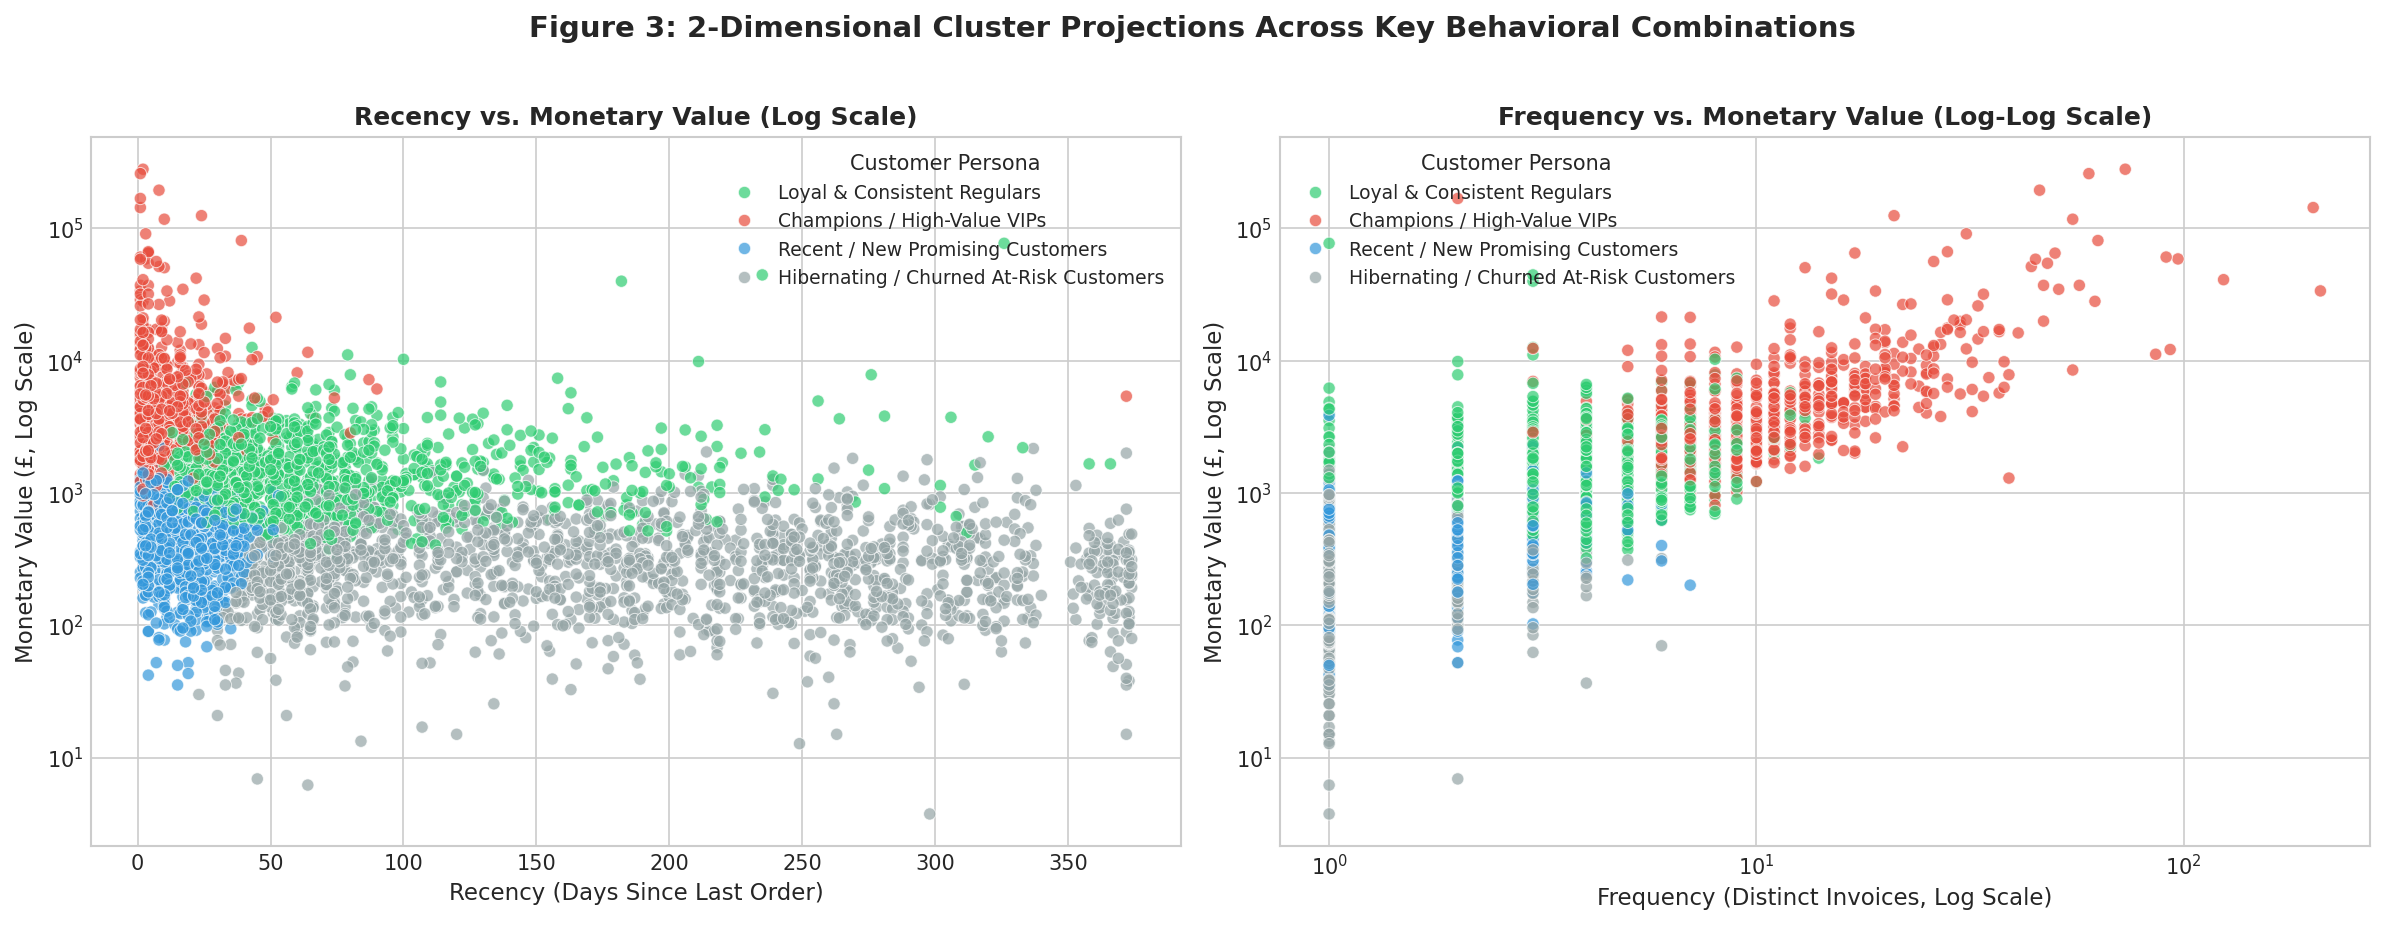

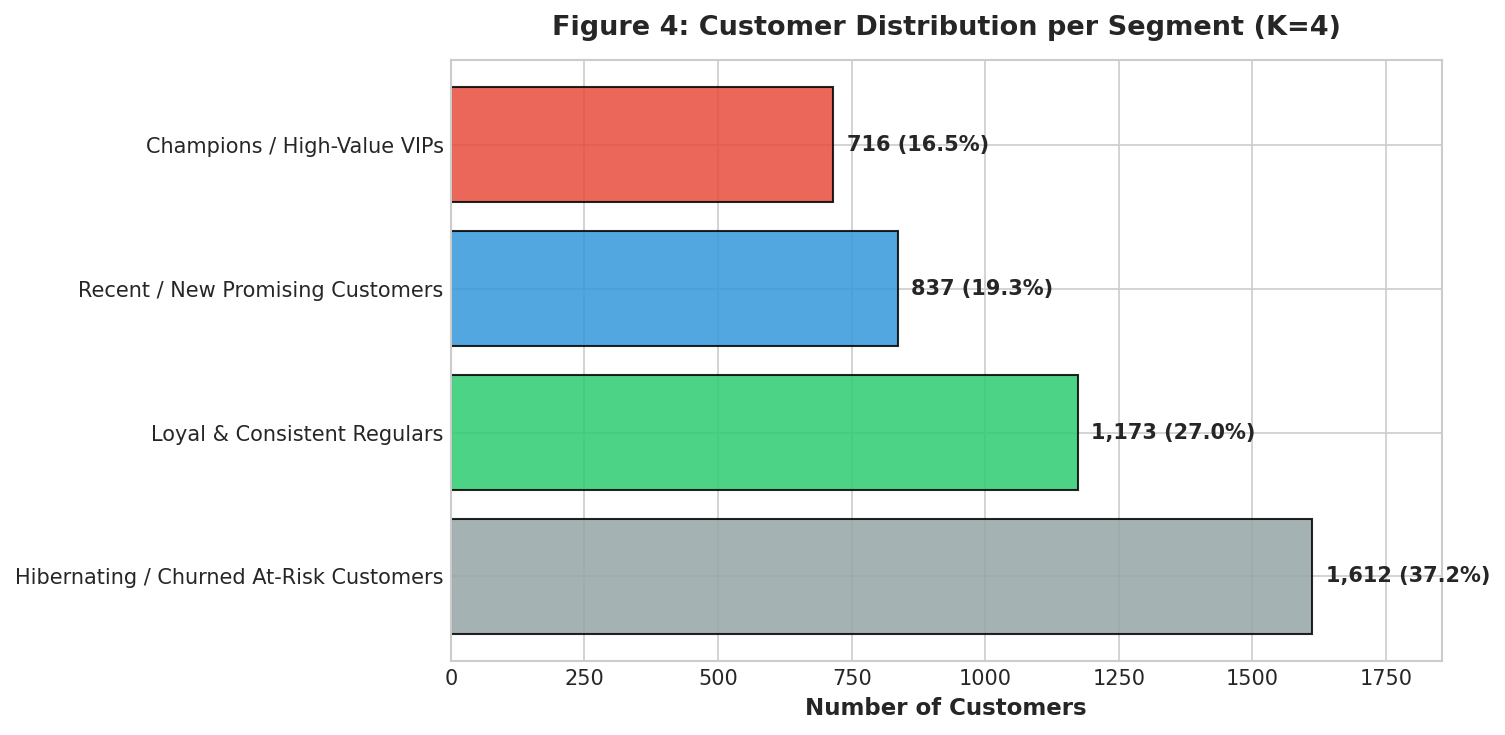

In [7]:
# Figure 3: 2D Scatter Plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
palette = {
    'Champions / High-Value VIPs': '#e74c3c',
    'Loyal & Consistent Regulars': '#2ecc71',
    'Recent / New Promising Customers': '#3498db',
    'Hibernating / Churned At-Risk Customers': '#95a5a6'
}

# Plot 1: Recency vs Monetary
sns.scatterplot(data=rfm, x='Recency', y='Monetary', hue='Persona', palette=palette, alpha=0.7, ax=axes[0], s=35)
axes[0].set_yscale('log')
axes[0].set_title('Recency vs. Monetary Value (Log Scale)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Recency (Days Since Last Order)', fontsize=11)
axes[0].set_ylabel('Monetary Value (£, Log Scale)', fontsize=11)
axes[0].legend(title='Customer Persona', loc='upper right', fontsize=9)

# Plot 2: Frequency vs Monetary
sns.scatterplot(data=rfm, x='Frequency', y='Monetary', hue='Persona', palette=palette, alpha=0.7, ax=axes[1], s=35)
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_title('Frequency vs. Monetary Value (Log-Log Scale)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Frequency (Distinct Invoices, Log Scale)', fontsize=11)
axes[1].set_ylabel('Monetary Value (£, Log Scale)', fontsize=11)
axes[1].legend(title='Customer Persona', loc='upper left', fontsize=9)

fig.suptitle('Figure 3: 2-Dimensional Cluster Projections Across Key Behavioral Combinations', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('outputs/figures/fig3_cluster_scatter_plots.png', dpi=300, bbox_inches='tight')
plt.show()

# Figure 4: Customer Distribution Bar Chart
plt.figure(figsize=(10, 5))
counts = rfm['Persona'].value_counts()
bars = plt.barh(counts.index, counts.values, color=['#95a5a6', '#2ecc71', '#3498db', '#e74c3c'], edgecolor='black', alpha=0.85)
plt.title('Figure 4: Customer Distribution per Segment (K=4)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Number of Customers', fontsize=11, fontweight='bold')
plt.xlim(0, counts.max() * 1.15)
for bar in bars:
    w = bar.get_width()
    pct = (w / len(rfm)) * 100
    plt.text(w + 25, bar.get_y() + bar.get_height()/2, f"{int(w):,} ({pct:.1f}%)", va='center', ha='left', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/figures/fig4_cluster_customer_counts.png', dpi=300)
plt.show()


## Section 6: Proposed Marketing Hypotheses & Experimental Playbook

> **Methodological Note on Hypothesis Testing:** All marketing recommendations outlined below represent **proposed business hypotheses** derived from behavioral segmentation. They do not constitute guaranteed revenue drivers and must be subjected to randomized controlled A/B testing (measuring incremental conversion, lift, and churn rates against holdout control groups) prior to enterprise-wide rollout.


In [8]:
marketing_matrix = pd.DataFrame([
    {
        'Persona': 'Champions / High-Value VIPs',
        'Customer_Count': int(profiles.loc['Champions / High-Value VIPs', 'Cluster_Customer_Count']),
        'Revenue_Share': f"{profiles.loc['Champions / High-Value VIPs', 'Revenue_Share_Pct']}%",
        'Characteristics': 'Ultra-recent (mean 12.1 days), high frequency (13.7 orders), highest spend (£8,074 mean)',
        'Strategic_Objective': 'Retain and reward loyalty; prevent defection to competitors',
        'Proposed_Marketing_Strategy': 'VIP concierge support, exclusive reward previews, early product access, personalized appreciation gifts'
    },
    {
        'Persona': 'Loyal & Consistent Regulars',
        'Customer_Count': int(profiles.loc['Loyal & Consistent Regulars', 'Cluster_Customer_Count']),
        'Revenue_Share': f"{profiles.loc['Loyal & Consistent Regulars', 'Revenue_Share_Pct']}%",
        'Characteristics': 'Steady purchase cadence (mean 71.1 days), moderate-to-high spend (£1,803 mean)',
        'Strategic_Objective': 'Upsell and cross-sell into higher-tier spending; elevate to VIP status',
        'Proposed_Marketing_Strategy': 'Multi-item bundle discounts, automated replenishment triggers, category cross-sell recommendations'
    },
    {
        'Persona': 'Recent / New Promising Customers',
        'Customer_Count': int(profiles.loc['Recent / New Promising Customers', 'Cluster_Customer_Count']),
        'Revenue_Share': f"{profiles.loc['Recent / New Promising Customers', 'Revenue_Share_Pct']}%",
        'Characteristics': 'Recently transacted (mean 18.1 days) but have only 1-2 orders; modest spend (£552 mean)',
        'Strategic_Objective': 'Cultivate habit and secure second/third purchases quickly',
        'Proposed_Marketing_Strategy': 'Welcome onboarding drip campaign, post-purchase satisfaction surveys, 15% discount on second purchase within 30 days'
    },
    {
        'Persona': 'Hibernating / Churned At-Risk Customers',
        'Customer_Count': int(profiles.loc['Hibernating / Churned At-Risk Customers', 'Cluster_Customer_Count']),
        'Revenue_Share': f"{profiles.loc['Hibernating / Churned At-Risk Customers', 'Revenue_Share_Pct']}%",
        'Characteristics': 'Dormant (>6 months inactivity, mean 182.5 days), 1-time buyers, low spend (£343 mean)',
        'Strategic_Objective': 'Win back reachable buyers; prune unengaged contacts to reduce marketing spend',
        'Proposed_Marketing_Strategy': 'High-incentive comeback discounts ("We miss you - $20 off"), clearance sale alerts, automated feedback inquiry'
    }
])

marketing_matrix.to_csv('outputs/tables/customer_segment_marketing_matrix.csv', index=False)
display(marketing_matrix)


,Persona,Customer_Count,Revenue_Share,Characteristics,Strategic_Objective,Proposed_Marketing_Strategy
0,Champions / High-Value VIPs,716,64.87%,"Ultra-recent (mean 12.1 days), high frequency ...",Retain and reward loyalty; prevent defection t...,"VIP concierge support, exclusive reward previe..."
1,Loyal & Consistent Regulars,1173,23.73%,"Steady purchase cadence (mean 71.1 days), mode...",Upsell and cross-sell into higher-tier spendin...,"Multi-item bundle discounts, automated repleni..."
2,Recent / New Promising Customers,837,5.18%,Recently transacted (mean 18.1 days) but have ...,Cultivate habit and secure second/third purcha...,"Welcome onboarding drip campaign, post-purchas..."
3,Hibernating / Churned At-Risk Customers,1612,6.21%,"Dormant (>6 months inactivity, mean 182.5 days...",Win back reachable buyers; prune unengaged con...,"High-incentive comeback discounts (""We miss yo..."


In [9]:
# Export segmented customer dataset
segmented_csv_path = 'data/rfm_customer_segments.csv'
rfm.to_csv(segmented_csv_path)
print(f"Segmented customer dataset exported to: {segmented_csv_path}")
print(f"Total customers saved: {len(rfm):,}")

# Assertions
assert len(rfm) == 4338, "Unexpected customer count!"
assert rfm.isnull().sum().sum() == 0, "Null values detected in segmented dataset!"
assert rfm['Cluster'].nunique() == 4, "Expected 4 clusters!"
assert (rfm['Monetary'] > 0).all(), "Non-positive monetary values detected!"

print("✓ All customer segmentation pipeline assertions successfully passed.")


Segmented customer dataset exported to: data/rfm_customer_segments.csv
Total customers saved: 4,338
✓ All customer segmentation pipeline assertions successfully passed.


## Section 7: Analytical Limitations & Business Caveats

1. **Unidentified Guest Checkouts:** Approximately 24.9% of transactions lacked a `CustomerID`. While excluded to maintain entity integrity, these unassigned transactions may alter macro-level revenue conclusions.
2. **Seasonality Distortion:** The dataset spans December 2010 to December 2011, capturing two consecutive holiday peak shopping seasons. Recency calculations for customers who buy gifts strictly in Q4 may categorize them as "dormant" during summer months.
3. **Wholesale vs. Retail Heterogeneity:** A subset of customers are bulk wholesale accounts (purchasing thousands of units), while others are individual end-consumers. While log transformation stabilized centroid estimation, a dedicated B2B vs. B2C classification prior to clustering would further sharpen persona boundaries.
4. **Modest Cluster Separation & Continuous Behavioral Overlap:** The silhouette score of 0.3371 confirms moderate cluster cohesion with continuous overlap along the behavioral continuum. Customers do not occupy discrete, isolated islands; rather, boundaries are heuristic operational partitions. Marketing playbooks must therefore be treated as testable hypotheses rather than guaranteed revenue levers.
